# Proyecto Semestral: Preprocesamiento y Clasificación de Enfermedades del Arroz (Paddy Doctor)

**Curso:** Visión por Computadora  
**Entorno de ejecución recomendado:** Google Colab (GPU T4 habilitada en *Entorno de ejecución → Cambiar tipo de entorno de ejecución*).

In [ ]:
import os
import zipfile
from google.colab import files

# 1. Subir credenciales de Kaggle
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Por favor, selecciona tu archivo 'kaggle.json' cuando se solicite:")
    uploaded = files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json
    print("Credenciales de Kaggle configuradas correctamente.")
else:
    print("El archivo kaggle.json ya existe.")

# 2. Descargar y descomprimir el dataset si no se ha descargado previamente
DATA_DIR = "./paddy_data"
if not os.path.exists(DATA_DIR):
    print("Descargando dataset Paddy Doctor...")
    try:
        # Ejecutar descarga e interceptar posibles errores de la API
        result = !kaggle competitions download -c paddy-disease-classification
        if any("403" in line for line in result):
            raise PermissionError("Error 403: Debes unirte a la competencia y aceptar sus reglas en https://www.kaggle.com/c/paddy-disease-classification/rules antes de poder descargar el dataset.")

        print("Descomprimiendo imágenes...")
        with zipfile.ZipFile("paddy-disease-classification.zip", 'r') as zip_ref:
            zip_ref.extractall(DATA_DIR)
        print("Dataset listo para usar.")
    except Exception as e:
        print("\n[ERROR] No se pudo descargar o descomprimir el dataset.")
        print(f"Detalle: {e}")
        print("\n👉 POR FAVOR: Ve a https://www.kaggle.com/c/paddy-disease-classification/rules, acepta las reglas con tu cuenta y vuelve a ejecutar esta celda.")
else:
    print("El dataset ya se encuentra descomprimido.")

El archivo kaggle.json ya existe.
Descargando dataset Paddy Doctor...
Descomprimiendo imágenes...
Dataset listo para usar.


In [ ]:
import cv2
import glob
import random
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import timm

# Configuración de Semilla para Reproducibilidad
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything()

# Configuración de Rutas y Dispositivo
TRAIN_DIR = Path("./paddy_data/train_images")
CSV_PATH = Path("./paddy_data/train.csv")
IMG_SIZE = (256, 256)
BATCH_SIZE = 32
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Dispositivo de cómputo en uso: {DEVICE}")

Dispositivo de cómputo en uso: cpu


Vista previa del DataFrame:


,image_id,label,variety,age
0,100330.jpg,bacterial_leaf_blight,ADT45,45
1,100365.jpg,bacterial_leaf_blight,ADT45,45
2,100382.jpg,bacterial_leaf_blight,ADT45,45
3,100632.jpg,bacterial_leaf_blight,ADT45,45
4,101918.jpg,bacterial_leaf_blight,ADT45,45



Total de imágenes registradas: 10407
Número de clases: 10



/tmp/ipykernel_5679/2792520389.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y='label', order=df['label'].value_counts().index, palette='viridis')


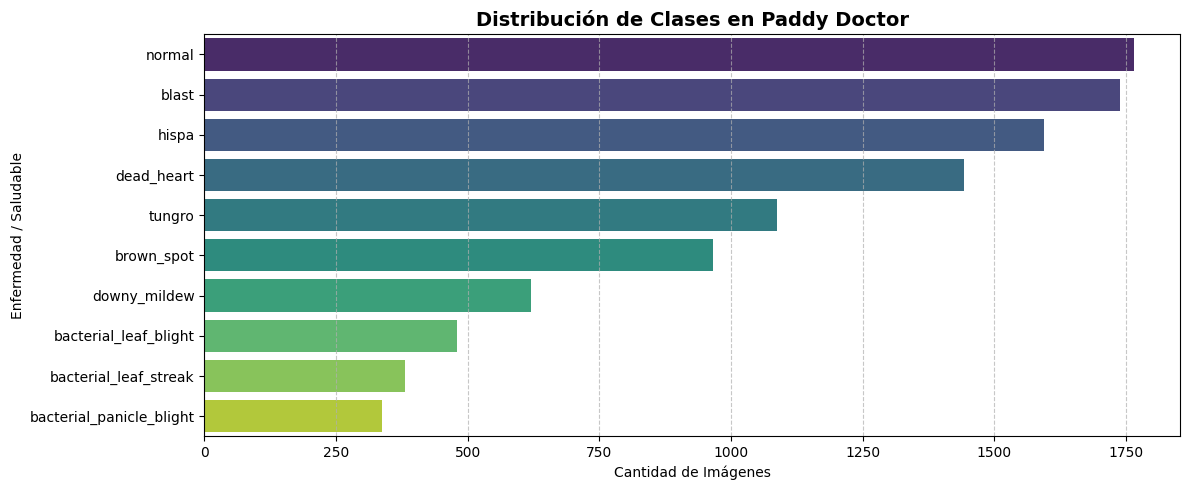

In [ ]:
# Cargar DataFrame de entrenamiento
df = pd.read_csv(CSV_PATH)
print("Vista previa del DataFrame:")
display(df.head())

print(f"\nTotal de imágenes registradas: {len(df)}")
print(f"Número de clases: {df['label'].nunique()}\n")

# Gráfico de distribución de clases
plt.figure(figsize=(12, 5))
sns.countplot(data=df, y='label', order=df['label'].value_counts().index, palette='viridis')
plt.title('Distribución de Clases en Paddy Doctor', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Imágenes')
plt.ylabel('Enfermedad / Saludable')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
def apply_clahe_lab(image_bgr, clip_limit=3.0, tile_size=(8, 8)):
    """
    Mejora el contraste adaptativo en el espacio de color LAB.
    Aplica CLAHE únicamente sobre el canal de Luminancia (L).
    """
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_enhanced = clahe.apply(l)

    lab_enhanced = cv2.merge((l_enhanced, a, b))
    rgb_enhanced = cv2.cvtColor(lab_enhanced, cv2.COLOR_LAB2RGB)
    return rgb_enhanced

def apply_hsv_mask(image_bgr):
    """
    Mascara el fondo no vegetal aislado en el espacio de color HSV.
    Mantiene principalmente las regiones dentro de la gama de verdes/amarillos foliares.
    """
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)

    # Rangos de color verde/amarillento típicos en hojas de arroz
    lower_green = np.array([25, 30, 30])
    upper_green = np.array([90, 255, 255])

    mask = cv2.inRange(hsv, lower_green, upper_green)
    masked_img = cv2.bitwise_and(image_bgr, image_bgr, mask=mask)
    return cv2.cvtColor(masked_img, cv2.COLOR_BGR2RGB)

def full_preprocessing_pipeline(image_path, target_size=IMG_SIZE):
    """
    Pipeline unificado de preprocesamiento:
    1. Lectura
    2. Filtrado CLAHE en espacio LAB
    3. Redimensionamiento
    """
    img_bgr = cv2.imread(str(image_path))
    if img_bgr is None:
        raise ValueError(f"No se pudo leer la imagen en {image_path}")

    enhanced_rgb = apply_clahe_lab(img_bgr)
    resized = cv2.resize(enhanced_rgb, target_size, interpolation=cv2.INTER_AREA)
    return resized

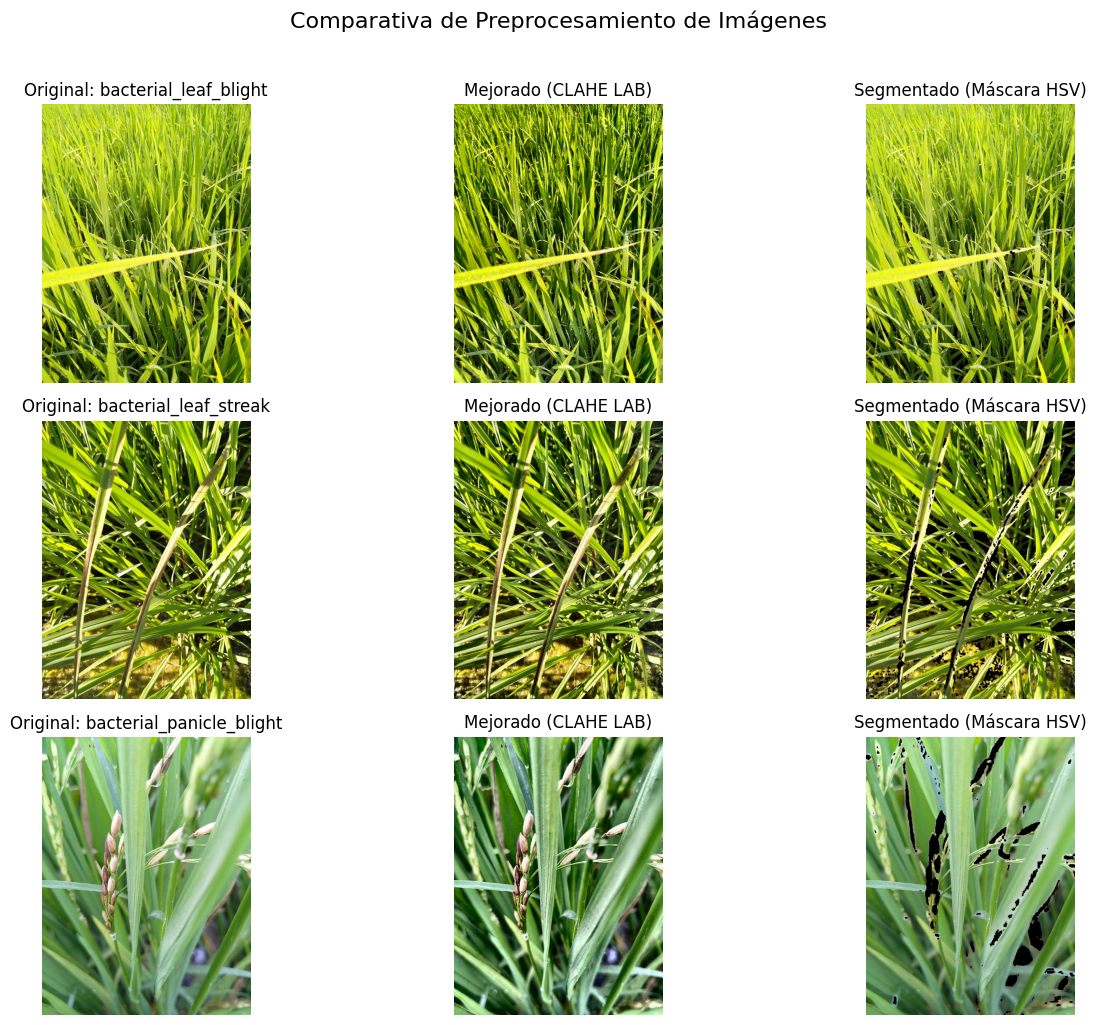

In [ ]:
# Tomar muestras aleatorias de 3 clases para comparar
sample_rows = df.groupby('label').sample(1, random_state=42).iloc[:3]

fig, axes = plt.subplots(len(sample_rows), 3, figsize=(14, 10))

for idx, (_, row) in enumerate(sample_rows.iterrows()):
    img_path = TRAIN_DIR / row['label'] / row['image_id']
    img_bgr = cv2.imread(str(img_path))
    img_rgb_orig = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    # Aplicar transformaciones
    img_clahe = apply_clahe_lab(img_bgr)
    img_masked = apply_hsv_mask(img_bgr)

    # Original
    axes[idx, 0].imshow(img_rgb_orig)
    axes[idx, 0].set_title(f"Original: {row['label']}")
    axes[idx, 0].axis('off')

    # CLAHE LAB
    axes[idx, 1].imshow(img_clahe)
    axes[idx, 1].set_title("Mejorado (CLAHE LAB)")
    axes[idx, 1].axis('off')

    # Máscara HSV
    axes[idx, 2].imshow(img_masked)
    axes[idx, 2].set_title("Segmentado (Máscara HSV)")
    axes[idx, 2].axis('off')

plt.suptitle("Comparativa de Preprocesamiento de Imágenes", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
class PaddyDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform

        # Mapeo de clases a enteros
        self.labels = sorted(self.df['label'].unique())
        self.label_to_idx = {lbl: idx for idx, lbl in enumerate(self.labels)}

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.img_dir / row['label'] / row['image_id']

        # Cargar y preprocesar
        image = full_preprocessing_pipeline(img_path, target_size=IMG_SIZE)
        label_idx = self.label_to_idx[row['label']]

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']

        return image, torch.tensor(label_idx, dtype=torch.long)

# Aumentos de datos
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.1, contrast=0.2, saturation=0.2, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=30, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# Instanciación de prueba del Dataset y DataLoader
train_dataset = PaddyDataset(df, TRAIN_DIR, transform=train_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)

# Verificación de forma de batch
sample_imgs, sample_lbls = next(iter(train_loader))
print(f"Dimensiones del tensor de imágenes en batch: {sample_imgs.shape}")
print(f"Dimensiones del tensor de etiquetas en batch: {sample_lbls.shape}")

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Dimensiones del tensor de imágenes en batch: torch.Size([32, 3, 256, 256])
Dimensiones del tensor de etiquetas en batch: torch.Size([32])


In [ ]:
class PaddyClassifier(nn.Module):
    def __init__(self, model_name='efficientnet_b0', num_classes=10, pretrained=True):
        super(PaddyClassifier, self).__init__()
        self.backbone = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)

    def forward(self, x):
        return self.backbone(x)

# Instanciar el modelo
num_classes = df['label'].nunique()
model = PaddyClassifier(model_name='efficientnet_b0', num_classes=num_classes, pretrained=True).to(DEVICE)

# Forward pass de prueba con un solo lote
sample_imgs = sample_imgs.to(DEVICE)
with torch.no_grad():
    outputs = model(sample_imgs)

print(f"Salida del modelo (Logits por clase): {outputs.shape}")
print("¡Pipeline listo para comenzar el entrenamiento!")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Salida del modelo (Logits por clase): torch.Size([32, 10])
¡Pipeline listo para comenzar el entrenamiento!
